In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import warnings as wr
wr.filterwarnings(action="ignore")
import seaborn as sns

### Read all datasets from multiple files

In [2]:
account = pd.read_csv("./Data/Customer Profiles/account_activity.csv")
customer = pd.read_csv("./Data/Customer Profiles/customer_data.csv")
train_fraud = pd.read_csv("./Data/Fraudulent Patterns/train_data.csv")
test_fraud = pd.read_csv("./Data/Fraudulent Patterns/test_data.csv")
suspision = pd.read_csv("./Data/Fraudulent Patterns/suspicious_activity.csv")
merchant = pd.read_csv("./Data/Merchant Information/merchant_data.csv")
tran_cat = pd.read_csv("./Data/Merchant Information/transaction_category_labels.csv")
tran_data = pd.read_csv("./Data/Transaction Data/transaction_metadata.csv")
tran_rec = pd.read_csv("./Data/Transaction Data/transaction_records.csv")

In [3]:
# Display part of data for each dataset
data = [account,customer,train_fraud,test_fraud,suspision,merchant,tran_cat,tran_data,tran_rec]

for df in data:
    print(df.head())
    print('-'*50)

  CustomerID  AccountBalance            LastLogin
0   CUST0001         1023.65  2023-07-06 09:52:17
1   CUST0002         3903.35  2023-07-30 09:53:21
2   CUST0003        10315.71  2022-05-21 03:58:36
3   CUST0004         6588.04  2023-09-23 21:21:57
4   CUST0005         8213.97  2022-09-03 08:49:39
--------------------------------------------------
  CustomerID               Name Sex  Age  Address
0   CUST0001  Christopher Owens   M   21     East
1   CUST0002       Rachel Lopez   F   50     West
2   CUST0003       Jerry Martin   M   24     West
3   CUST0004      Jennifer Tran   M   23  Central
4   CUST0005        Jason Smith   M   19  Central
--------------------------------------------------
  TransactionID  FraudIndicator
0   TRANS013267               0
1   TRANS016627               0
2   TRANS000729               0
3   TRANS019871               0
4   TRANS008463               0
--------------------------------------------------
  TransactionID  FraudIndicator
0   TRANS015754        

In [110]:
# Customer data generation
customer_data = pd.merge(customer, account, on='CustomerID')
customer_data = pd.merge(customer_data, suspision, on='CustomerID')
customer_data

,CustomerID,Name,Sex,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,CUST0001,Christopher Owens,M,21,East,1023.65,2023-07-06 09:52:17,0
1,CUST0002,Rachel Lopez,F,50,West,3903.35,2023-07-30 09:53:21,0
2,CUST0003,Jerry Martin,M,24,West,10315.71,2022-05-21 03:58:36,0
3,CUST0004,Jennifer Tran,M,23,Central,6588.04,2023-09-23 21:21:57,0
4,CUST0005,Jason Smith,M,19,Central,8213.97,2022-09-03 08:49:39,0
...,...,...,...,...,...,...,...,...
995,CUST0996,Mary Turner,F,18,East,5349.47,2023-09-07 14:42:45,0
996,CUST0997,Amanda Miller,F,40,East,15688.16,2023-11-08 11:38:08,0
997,CUST0998,Bonnie Buck,F,19,South,357.25,2023-11-29 05:05:40,0
998,CUST0999,Christine Wilson,F,50,South,293.74,2022-01-27 23:51:44,1


In [111]:
# Transaction data generation
transaction_data1 = pd.merge(train_fraud, tran_cat, on="TransactionID")
transaction_data2 = pd.merge(tran_data, tran_rec, on="TransactionID")
train_transaction_data = pd.merge(transaction_data1, transaction_data2,on="TransactionID")
train_transaction_data

,TransactionID,FraudIndicator,Category,Timestamp,MerchantID,Amount,CustomerID
0,TRANS013267,0,Electronics,2022-04-28 04:59:02,MERCH003,457.90,CUST0654
1,TRANS016627,0,Kitchen,2023-12-22 18:11:55,MERCH018,113.59,CUST0818
2,TRANS000729,0,Kitchen,2022-01-22 04:59:48,MERCH004,103.64,CUST0036
3,TRANS019871,0,Furniture,2023-08-25 01:00:05,MERCH001,235.43,CUST0975
4,TRANS008463,0,Food,2022-08-27 14:20:31,MERCH007,289.47,CUST0416
...,...,...,...,...,...,...,...
16307,TRANS001437,0,Bathroom,2023-05-29 11:26:35,MERCH019,70.39,CUST0071
16308,TRANS017606,1,Electronics,2022-07-25 05:10:41,MERCH020,135.58,CUST0866
16309,TRANS007258,1,Kitchen,2022-02-18 22:40:45,MERCH014,63.37,CUST0360
16310,TRANS016569,1,Food,2022-03-18 22:43:33,MERCH001,32.20,CUST0815


In [112]:
transaction_data1 = pd.merge(test_fraud, tran_cat, on="TransactionID")
transaction_data2 = pd.merge(tran_data, tran_rec, on="TransactionID")
test_transaction_data = pd.merge(transaction_data1, transaction_data2,on="TransactionID")
test_transaction_data

,TransactionID,FraudIndicator,Category,Timestamp,MerchantID,Amount,CustomerID
0,TRANS015754,0,Furniture,2022-01-24 23:22:25,MERCH012,94.28,CUST0776
1,TRANS008941,1,Kitchen,2022-03-01 11:39:45,MERCH016,247.90,CUST0440
2,TRANS009578,0,Food,2022-07-28 00:08:42,MERCH017,311.41,CUST0472
3,TRANS018718,0,Food,2023-12-03 07:59:10,MERCH011,175.04,CUST0920
4,TRANS001315,0,Food,2022-08-08 06:02:53,MERCH020,2.90,CUST0064
...,...,...,...,...,...,...,...
4074,TRANS001407,1,Electronics,2022-04-10 14:24:31,MERCH004,330.44,CUST0069
4075,TRANS012768,1,Other,2022-05-01 08:11:17,MERCH013,131.39,CUST0631
4076,TRANS020299,0,Kitchen,2023-04-12 07:29:51,MERCH009,323.87,CUST0996
4077,TRANS001158,1,Food,2022-09-23 04:42:43,MERCH017,314.76,CUST0056


In [113]:
# Merge transaction data with customer data
train_data = pd.merge(train_transaction_data, customer_data,on="CustomerID")
train_data

,TransactionID,FraudIndicator,Category,Timestamp,MerchantID,Amount,CustomerID,Name,Sex,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,TRANS013267,0,Electronics,2022-04-28 04:59:02,MERCH003,457.90,CUST0654,Leslie Hill,M,25,East,2232.50,2023-01-13 07:18:22,0
1,TRANS016627,0,Kitchen,2023-12-22 18:11:55,MERCH018,113.59,CUST0818,Ashley Peterson,F,21,South,7331.52,2022-12-25 09:20:40,0
2,TRANS000729,0,Kitchen,2022-01-22 04:59:48,MERCH004,103.64,CUST0036,Jeffrey White,M,25,Central,5958.39,2022-06-16 16:42:30,0
3,TRANS019871,0,Furniture,2023-08-25 01:00:05,MERCH001,235.43,CUST0975,Gregory Case,M,18,South,1774.28,2022-10-09 15:25:49,0
4,TRANS008463,0,Food,2022-08-27 14:20:31,MERCH007,289.47,CUST0416,Monica Decker,F,22,South,13791.91,2022-11-17 21:44:06,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16307,TRANS001437,0,Bathroom,2023-05-29 11:26:35,MERCH019,70.39,CUST0071,Phillip Hughes,F,25,West,1757.07,2022-09-11 21:41:34,0
16308,TRANS017606,1,Electronics,2022-07-25 05:10:41,MERCH020,135.58,CUST0866,Lauren Mckee,M,23,West,13854.00,2023-07-12 14:06:33,0
16309,TRANS007258,1,Kitchen,2022-02-18 22:40:45,MERCH014,63.37,CUST0360,Steven Coffey,M,23,East,4486.74,2023-11-12 12:55:31,1
16310,TRANS016569,1,Food,2022-03-18 22:43:33,MERCH001,32.20,CUST0815,Jon Hicks,F,30,North,428.72,2022-01-12 09:39:21,0


In [114]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16312 entries, 0 to 16311
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   TransactionID   16312 non-null  object 
 1   FraudIndicator  16312 non-null  int64  
 2   Category        16312 non-null  object 
 3   Timestamp       16312 non-null  object 
 4   MerchantID      16312 non-null  object 
 5   Amount          16312 non-null  float64
 6   CustomerID      16312 non-null  object 
 7   Name            16312 non-null  object 
 8   Sex             16312 non-null  object 
 9   Age             16312 non-null  int64  
 10  Address         16312 non-null  object 
 11  AccountBalance  16312 non-null  float64
 12  LastLogin       16312 non-null  object 
 13  SuspiciousFlag  16312 non-null  int64  
dtypes: float64(2), int64(3), object(9)
memory usage: 1.7+ MB


In [115]:
test_data = pd.merge(test_transaction_data, customer_data,on="CustomerID")
test_data

,TransactionID,FraudIndicator,Category,Timestamp,MerchantID,Amount,CustomerID,Name,Sex,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,TRANS015754,0,Furniture,2022-01-24 23:22:25,MERCH012,94.28,CUST0776,Mark Thomas,F,19,South,1894.65,2022-02-27 08:28:10,0
1,TRANS008941,1,Kitchen,2022-03-01 11:39:45,MERCH016,247.90,CUST0440,Ian Erickson,M,18,East,5595.59,2023-04-07 22:33:07,0
2,TRANS009578,0,Food,2022-07-28 00:08:42,MERCH017,311.41,CUST0472,Robert Lynch,F,50,North,6705.63,2023-12-29 22:13:08,1
3,TRANS018718,0,Food,2023-12-03 07:59:10,MERCH011,175.04,CUST0920,Christine Moore,F,19,Central,2660.43,2023-11-29 14:37:34,0
4,TRANS001315,0,Food,2022-08-08 06:02:53,MERCH020,2.90,CUST0064,Michael Harper,M,21,North,2704.42,2022-08-15 07:58:41,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4074,TRANS001407,1,Electronics,2022-04-10 14:24:31,MERCH004,330.44,CUST0069,James Solis,M,18,North,2189.60,2023-04-28 19:34:13,0
4075,TRANS012768,1,Other,2022-05-01 08:11:17,MERCH013,131.39,CUST0631,Elizabeth Harvey,F,24,East,7056.28,2022-09-19 03:44:47,1
4076,TRANS020299,0,Kitchen,2023-04-12 07:29:51,MERCH009,323.87,CUST0996,Mary Turner,F,18,East,5349.47,2023-09-07 14:42:45,0
4077,TRANS001158,1,Food,2022-09-23 04:42:43,MERCH017,314.76,CUST0056,Teresa Gomez,M,40,West,2159.39,2022-03-05 04:18:15,1


In [116]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4079 entries, 0 to 4078
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   TransactionID   4079 non-null   object 
 1   FraudIndicator  4079 non-null   int64  
 2   Category        4079 non-null   object 
 3   Timestamp       4079 non-null   object 
 4   MerchantID      4079 non-null   object 
 5   Amount          4079 non-null   float64
 6   CustomerID      4079 non-null   object 
 7   Name            4079 non-null   object 
 8   Sex             4079 non-null   object 
 9   Age             4079 non-null   int64  
 10  Address         4079 non-null   object 
 11  AccountBalance  4079 non-null   float64
 12  LastLogin       4079 non-null   object 
 13  SuspiciousFlag  4079 non-null   int64  
dtypes: float64(2), int64(3), object(9)
memory usage: 446.3+ KB


In [117]:
# Feature engineering for hour and gap
train_data['Timestamp'] = pd.to_datetime(train_data['Timestamp'])
train_data['Hour'] = train_data['Timestamp'].dt.hour
train_data['LastLogin'] = pd.to_datetime(train_data['LastLogin'])
train_data['gap'] = (train_data['Timestamp'] - train_data['LastLogin']).dt.days.abs()
train_data.head()

,TransactionID,FraudIndicator,Category,Timestamp,MerchantID,Amount,CustomerID,Name,Sex,Age,Address,AccountBalance,LastLogin,SuspiciousFlag,Hour,gap
0,TRANS013267,0,Electronics,2022-04-28 04:59:02,MERCH003,457.90,CUST0654,Leslie Hill,M,25,East,2232.50,2023-01-13 07:18:22,0,4,261
1,TRANS016627,0,Kitchen,2023-12-22 18:11:55,MERCH018,113.59,CUST0818,Ashley Peterson,F,21,South,7331.52,2022-12-25 09:20:40,0,18,362
2,TRANS000729,0,Kitchen,2022-01-22 04:59:48,MERCH004,103.64,CUST0036,Jeffrey White,M,25,Central,5958.39,2022-06-16 16:42:30,0,4,146
3,TRANS019871,0,Furniture,2023-08-25 01:00:05,MERCH001,235.43,CUST0975,Gregory Case,M,18,South,1774.28,2022-10-09 15:25:49,0,1,319
4,TRANS008463,0,Food,2022-08-27 14:20:31,MERCH007,289.47,CUST0416,Monica Decker,F,22,South,13791.91,2022-11-17 21:44:06,0,14,83


In [118]:
test_data['Timestamp'] = pd.to_datetime(test_data['Timestamp'])
test_data['Hour'] = test_data['Timestamp'].dt.hour
test_data['LastLogin'] = pd.to_datetime(test_data['LastLogin'])
test_data['gap'] = (test_data['Timestamp'] - test_data['LastLogin']).dt.days.abs()
test_data.head()

,TransactionID,FraudIndicator,Category,Timestamp,MerchantID,Amount,CustomerID,Name,Sex,Age,Address,AccountBalance,LastLogin,SuspiciousFlag,Hour,gap
0,TRANS015754,0,Furniture,2022-01-24 23:22:25,MERCH012,94.28,CUST0776,Mark Thomas,F,19,South,1894.65,2022-02-27 08:28:10,0,23,34
1,TRANS008941,1,Kitchen,2022-03-01 11:39:45,MERCH016,247.90,CUST0440,Ian Erickson,M,18,East,5595.59,2023-04-07 22:33:07,0,11,403
2,TRANS009578,0,Food,2022-07-28 00:08:42,MERCH017,311.41,CUST0472,Robert Lynch,F,50,North,6705.63,2023-12-29 22:13:08,1,0,520
3,TRANS018718,0,Food,2023-12-03 07:59:10,MERCH011,175.04,CUST0920,Christine Moore,F,19,Central,2660.43,2023-11-29 14:37:34,0,7,3
4,TRANS001315,0,Food,2022-08-08 06:02:53,MERCH020,2.90,CUST0064,Michael Harper,M,21,North,2704.42,2022-08-15 07:58:41,0,6,8


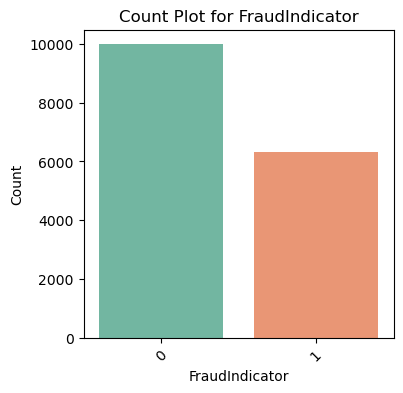

In [119]:
# We should use countplot for FraudIndicator feature
plt.figure(figsize=(4, 4))  # Adjust the figure size if needed
sns.countplot(x='FraudIndicator', data=train_data, palette='Set2')  # You can change the palette as desired
plt.title('Count Plot for FraudIndicator')
plt.xlabel('FraudIndicator')
plt.ylabel('Count')
plt.xticks(rotation=45)  # Rotate x-axis labels if they are long

plt.show()

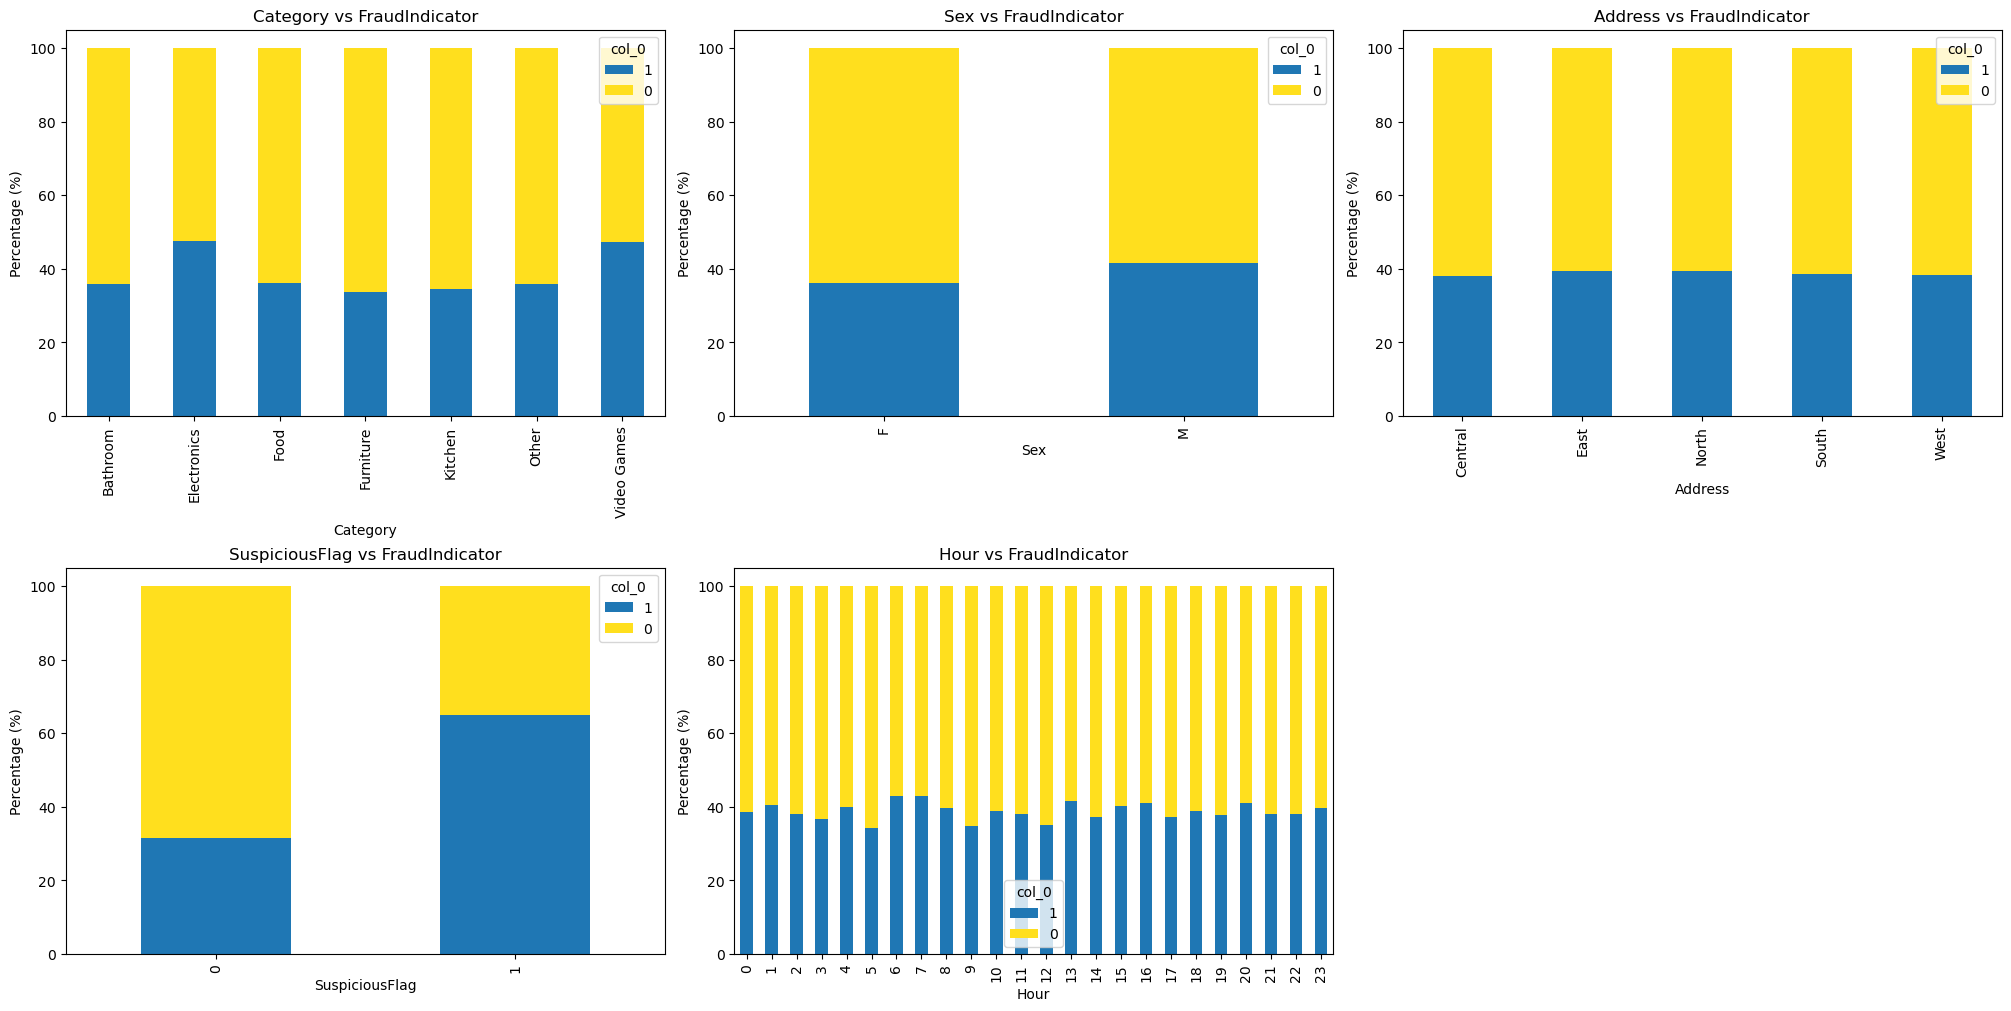

In [120]:
import pandas as pd
import math
import matplotlib.pyplot as plt

# 類別型輸入屬性列表
input_cols = ['Category','Sex','Address','SuspiciousFlag','Hour']
target_col = 'FraudIndicator'

# 指定目標屬性的顯示順序和顏色
desired_order = [1, 0]  # 自定義顯示順序
custom_colors = ['#1f77b4', '#ffdf1e']  # 自定義顏色列表

# 計算行列數
n_cols = 3  # 每行顯示的圖數
n_rows = math.ceil(len(input_cols) / n_cols)

# 創建子圖
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows), constrained_layout=True)
axes = axes.flatten()  # 將子圖對象展平以便迭代

# 繪製每個屬性的百分百堆疊圖
for i, col in enumerate(input_cols):
    ax = axes[i]
    
    # 計算類別分佈
    category_counts = pd.crosstab(train_data[col], pd.Categorical(train_data[target_col], categories=desired_order, ordered=True), normalize='index') * 100
    
    # 繪製百分百堆疊圖
    category_counts.plot(kind='bar', stacked=True, ax=ax, color=custom_colors)
    
    # 添加標籤和標題
    ax.set_title(f'{col} vs {target_col}')
    ax.set_ylabel('Percentage (%)')
    ax.set_xlabel(col)  # 動態設置為當前屬性名稱

# 刪除多餘的子圖
for j in range(len(input_cols), len(axes)):
    fig.delaxes(axes[j])

# 顯示圖表
plt.show()

In [121]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Initialize encoders
label_encoder = LabelEncoder()
one_hot_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# Process 'Sex' column using LabelEncoder
train_data['Sex'] = label_encoder.fit_transform(train_data['Sex'])
test_data['Sex'] = label_encoder.transform(test_data['Sex'])

# Process 'Category' and 'Address' columns using One-Hot Encoding
# For 'Category'
category_encoded_data1 = pd.DataFrame(
    one_hot_encoder.fit_transform(train_data[['Category']]),
    columns=one_hot_encoder.get_feature_names_out(['Category'])
)
category_encoded_data2 = pd.DataFrame(
    one_hot_encoder.transform(test_data[['Category']]),
    columns=one_hot_encoder.get_feature_names_out(['Category'])
)

# Merge the One-Hot Encoded 'Category' back to the original data
train_data = pd.concat([train_data.drop(columns=['Category']), category_encoded_data1], axis=1)
test_data = pd.concat([test_data.drop(columns=['Category']), category_encoded_data2], axis=1)

# For 'Address'
address_encoded_data1 = pd.DataFrame(
    one_hot_encoder.fit_transform(train_data[['Address']]),
    columns=one_hot_encoder.get_feature_names_out(['Address'])
)
address_encoded_data2 = pd.DataFrame(
    one_hot_encoder.transform(test_data[['Address']]),
    columns=one_hot_encoder.get_feature_names_out(['Address'])
)

# Merge the One-Hot Encoded 'Address' back to the original data
train_data = pd.concat([train_data.drop(columns=['Address']), address_encoded_data1], axis=1)
test_data = pd.concat([test_data.drop(columns=['Address']), address_encoded_data2], axis=1)

#train_data, test_data

In [122]:
train_data.shape, test_data.shape

((16312, 26), (4079, 26))

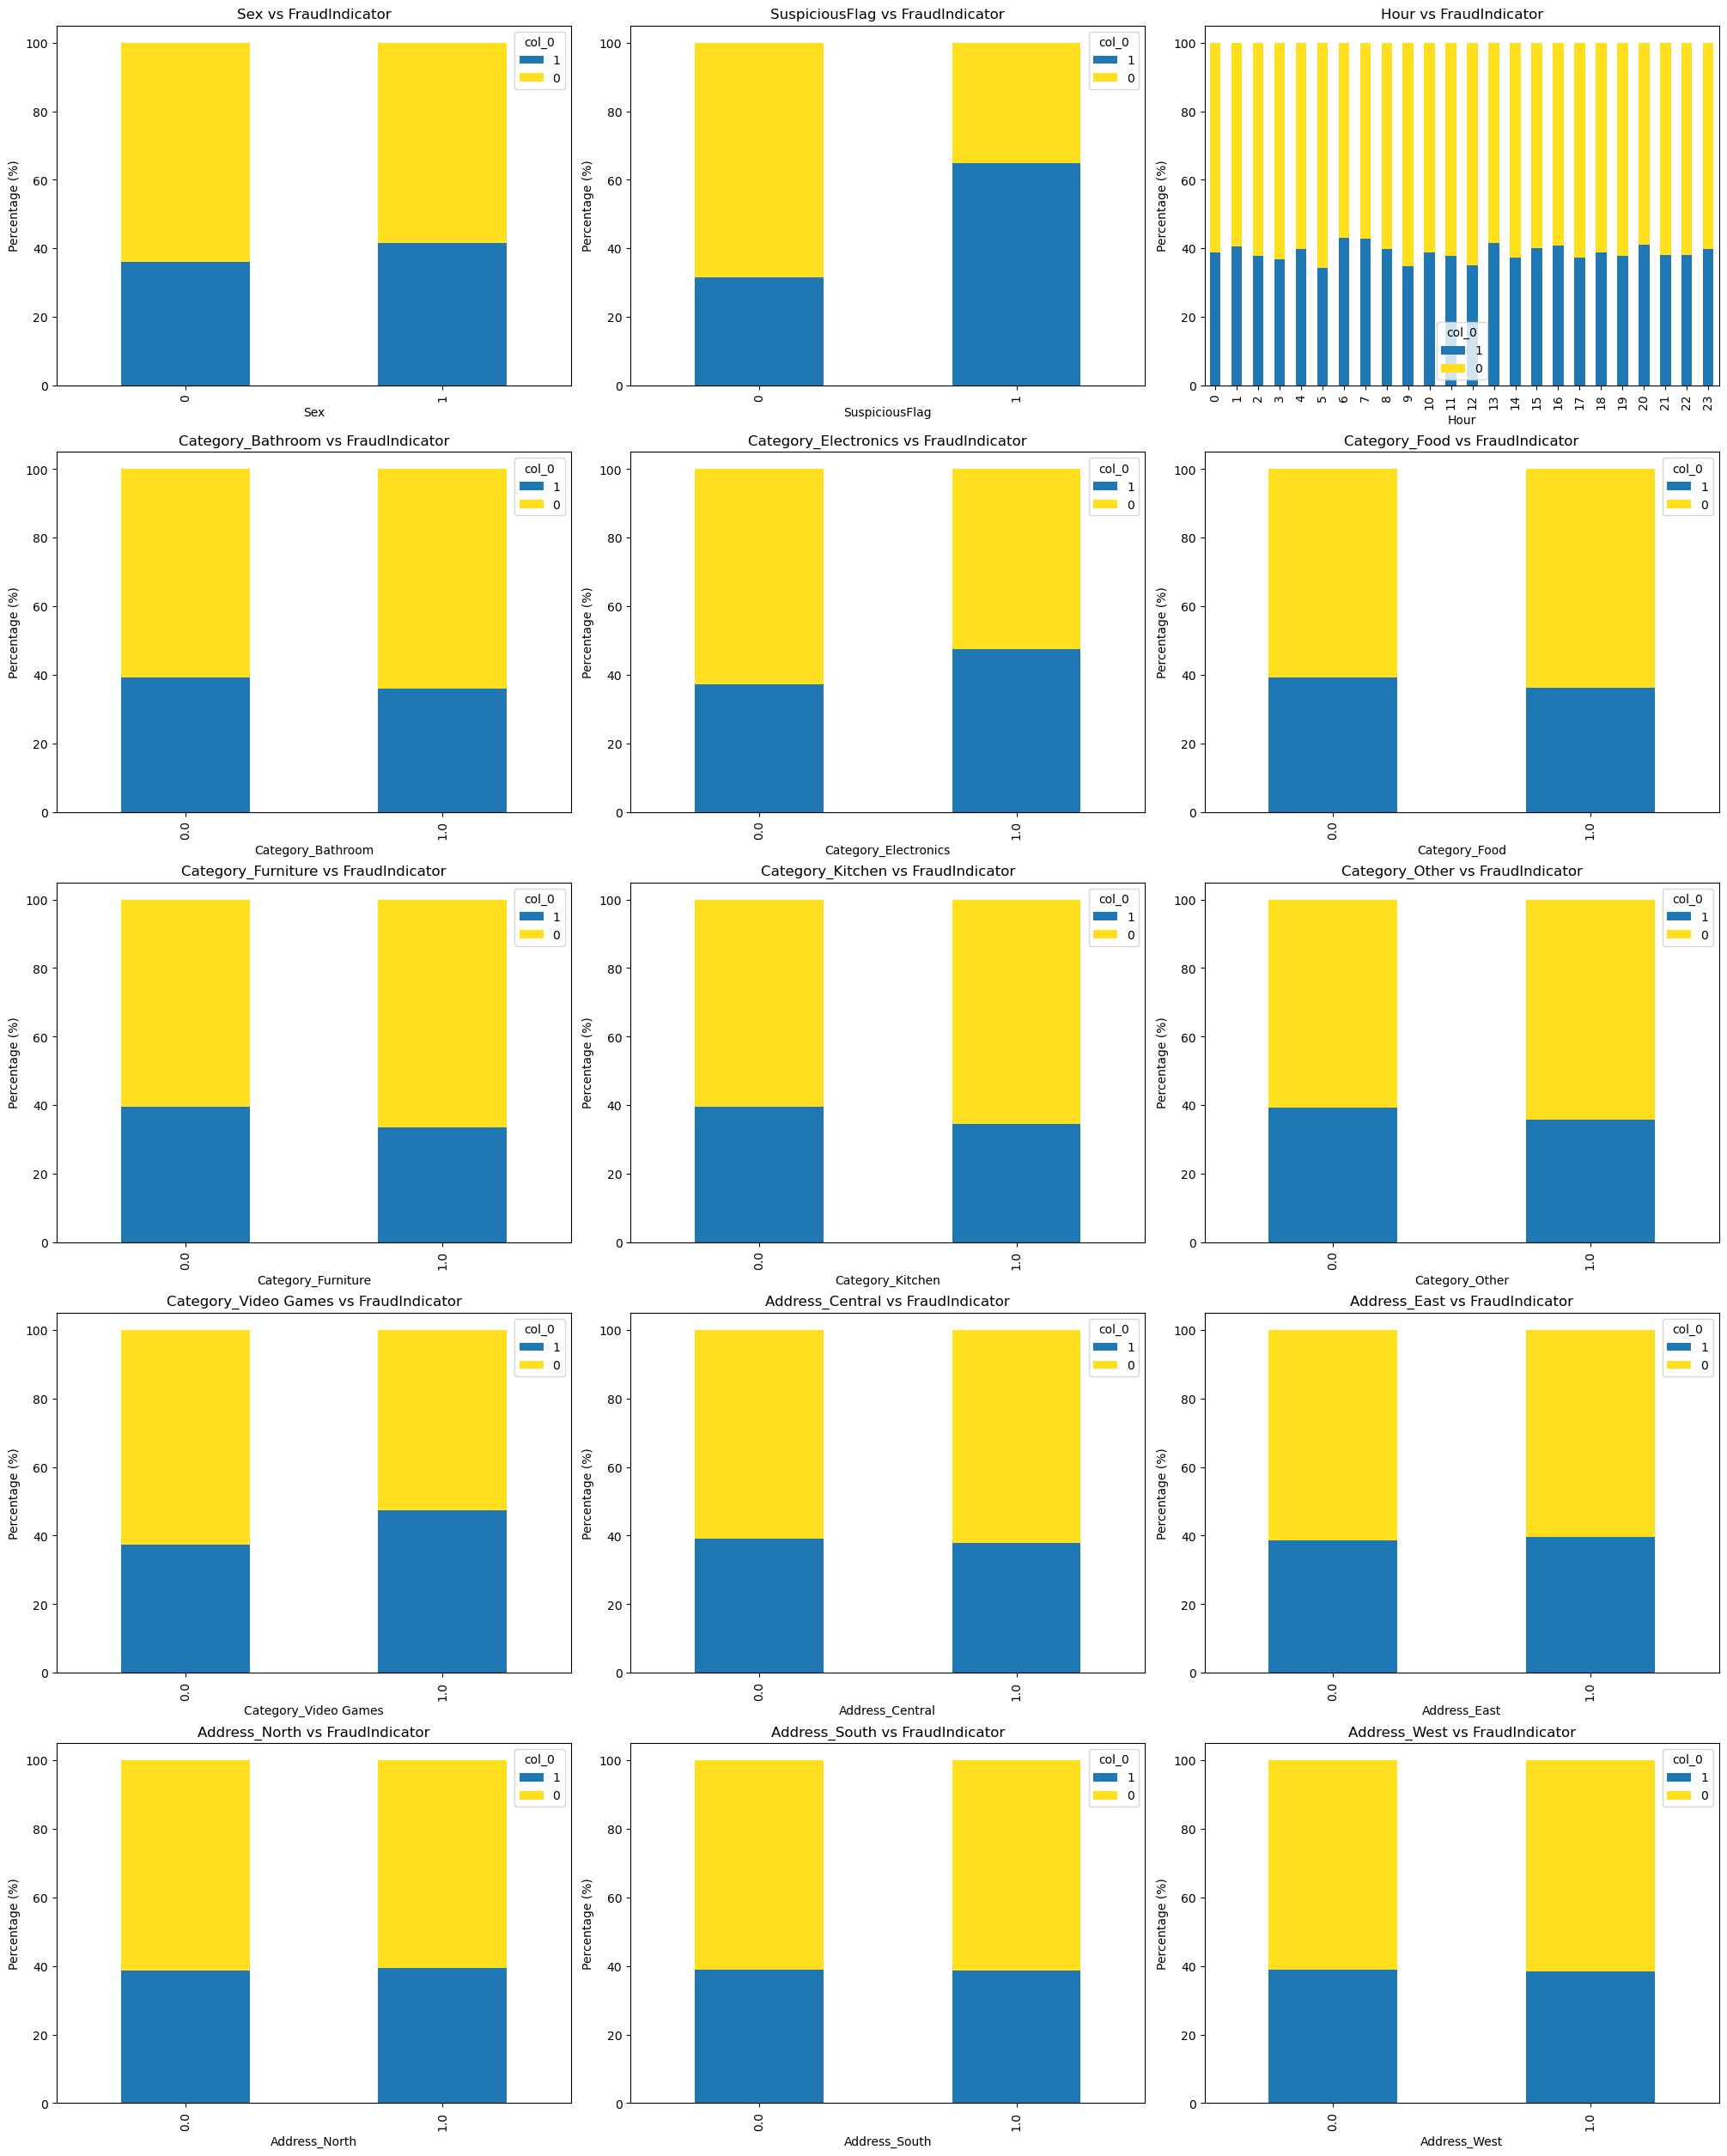

In [123]:
import pandas as pd
import math
import matplotlib.pyplot as plt

# 類別型輸入屬性列表
input_cols = ['Sex', 'SuspiciousFlag','Hour', 'Category_Bathroom', 'Category_Electronics', 'Category_Food', 'Category_Furniture',\
              'Category_Kitchen', 'Category_Other', 'Category_Video Games', 'Address_Central', 'Address_East', 'Address_North', \
              'Address_South', 'Address_West']
target_col = 'FraudIndicator'

# 指定目標屬性的顯示順序和顏色
desired_order = [1, 0]  # 自定義顯示順序
custom_colors = ['#1f77b4', '#ffdf1e']  # 自定義顏色列表

# 計算行列數
n_cols = 3  # 每行顯示的圖數
n_rows = math.ceil(len(input_cols) / n_cols)

# 創建子圖
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows), constrained_layout=True)
axes = axes.flatten()  # 將子圖對象展平以便迭代

# 繪製每個屬性的百分百堆疊圖
for i, col in enumerate(input_cols):
    ax = axes[i]
    
    # 計算類別分佈
    category_counts = pd.crosstab(train_data[col], pd.Categorical(train_data[target_col], categories=desired_order, ordered=True), normalize='index') * 100
    
    # 繪製百分百堆疊圖
    category_counts.plot(kind='bar', stacked=True, ax=ax, color=custom_colors)
    
    # 添加標籤和標題
    ax.set_title(f'{col} vs {target_col}')
    ax.set_ylabel('Percentage (%)')
    ax.set_xlabel(col)  # 動態設置為當前屬性名稱

# 刪除多餘的子圖
for j in range(len(input_cols), len(axes)):
    fig.delaxes(axes[j])

# 顯示圖表
plt.show()

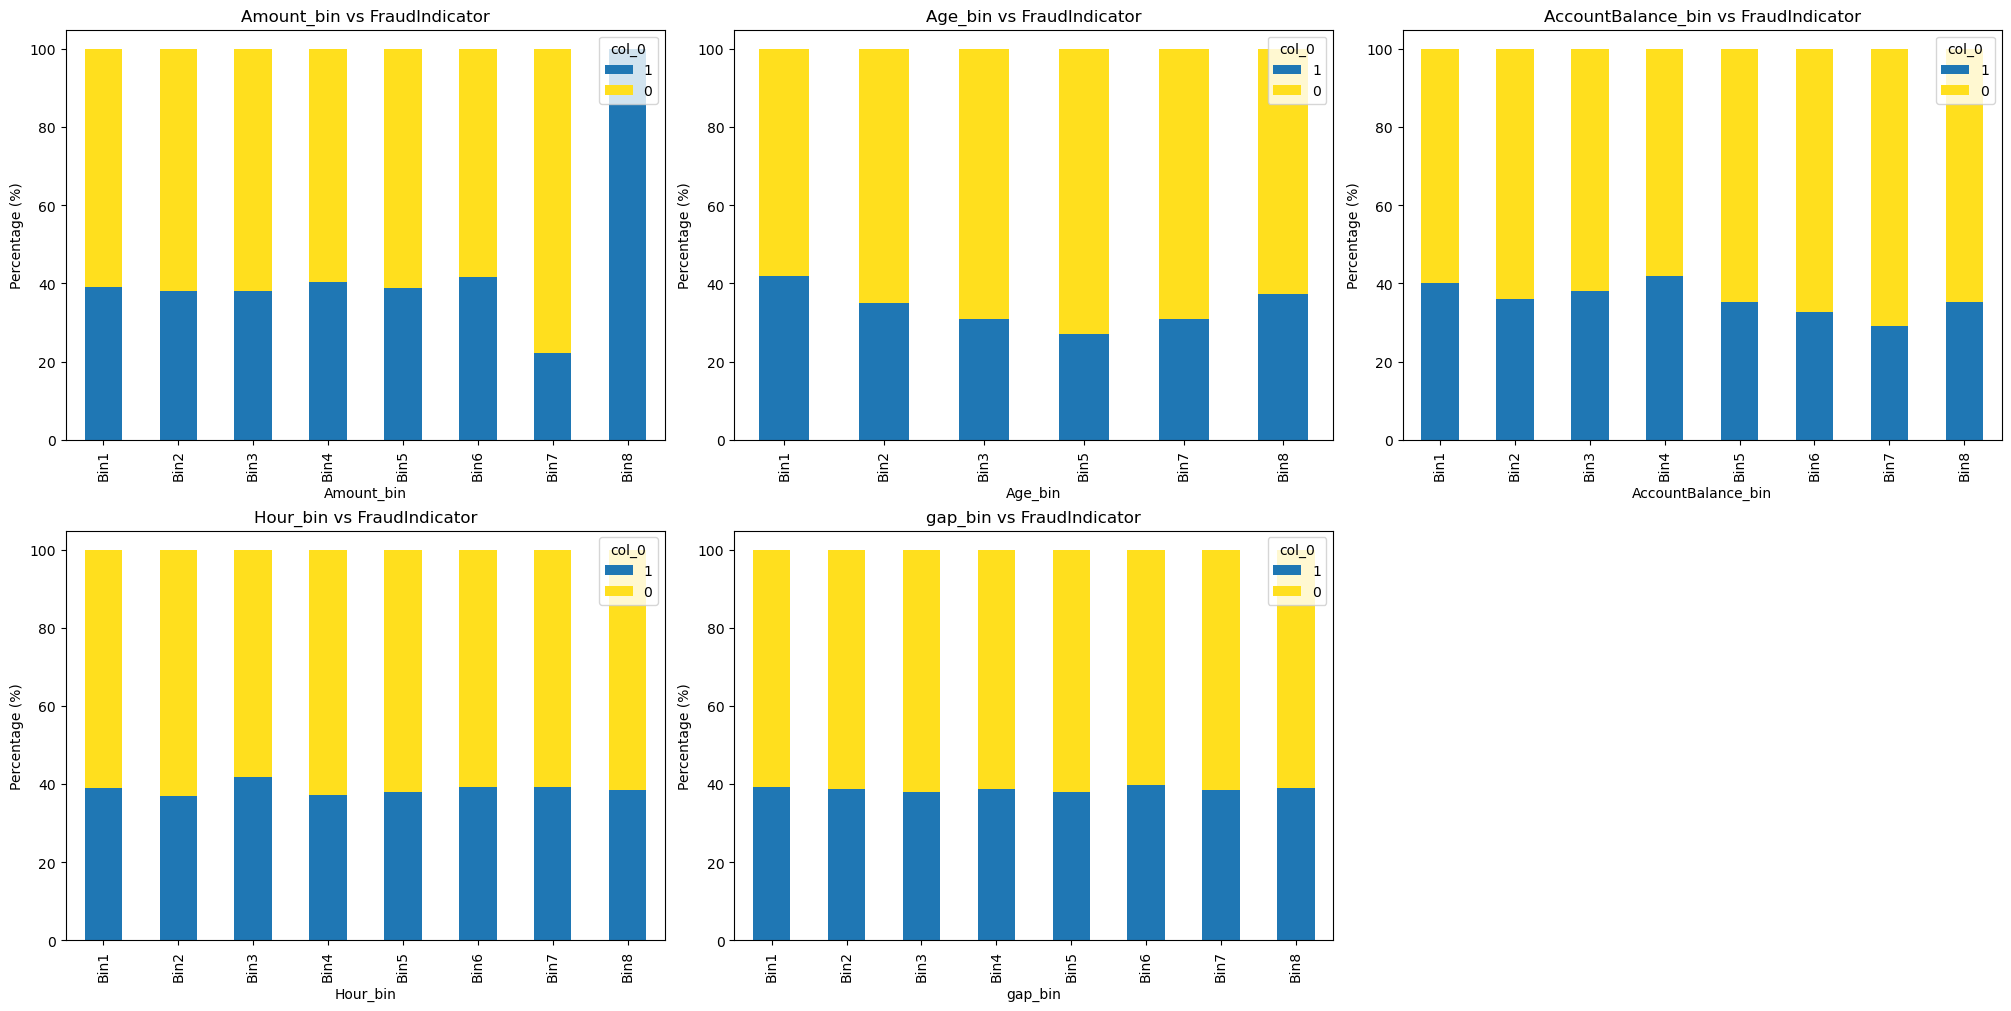

In [124]:
import pandas as pd
import matplotlib.pyplot as plt
import math

# 數值型輸入屬性列表
numeric_cols = ['Amount','Age','AccountBalance','Hour','gap']
target_col = 'FraudIndicator'

# 指定目標屬性的顯示順序和顏色
desired_order = [1, 0]  # 自定義顯示順序
custom_colors = ['#1f77b4', '#ffdf1e']  # 自定義顏色列表

# 分箱數目
bins = 8

# 將數值型屬性進行分箱處理
for col in numeric_cols:
    train_data[col + '_bin'] = pd.cut(train_data[col], bins=bins, labels=[f'Bin{i+1}' for i in range(bins)])

# 獲取離散化後的新屬性
binned_cols = [col + '_bin' for col in numeric_cols]

# 計算行列數
n_cols = 3  # 每行顯示的圖數
n_rows = math.ceil(len(binned_cols) / n_cols)

# 創建子圖
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows), constrained_layout=True)
axes = axes.flatten()  # 將子圖對象展平以便迭代

# 繪製每個屬性的百分百堆疊圖
for i, col in enumerate(binned_cols):
    ax = axes[i]
    
    # 計算類別分佈
    category_counts = pd.crosstab(train_data[col], pd.Categorical(train_data[target_col], categories=desired_order, ordered=True), normalize='index') * 100

    # 繪製百分百堆疊圖
    category_counts.plot(kind='bar', stacked=True, ax=ax, colormap='viridis', color=custom_colors)
    
    # 添加標籤和標題
    ax.set_title(f'{col} vs {target_col}')
    ax.set_ylabel('Percentage (%)')
    ax.set_xlabel(col)

# 刪除多餘的子圖
for j in range(len(binned_cols), len(axes)):
    fig.delaxes(axes[j])

# 顯示圖表
plt.show()

train_data = train_data.drop(columns=binned_cols, axis=1)

In [125]:
train_data.shape, test_data.shape

((16312, 26), (4079, 26))

In [126]:
# Dropping the columns as of now they are not mush corelated & also wouldn't damper the performance of model
columns_to_be_dropped = ['TransactionID','Timestamp','MerchantID','CustomerID','Name','LastLogin']

In [127]:
data1 = train_data.drop(columns_to_be_dropped, axis=1)
data1.head()

,FraudIndicator,Amount,Sex,Age,AccountBalance,SuspiciousFlag,Hour,gap,Category_Bathroom,Category_Electronics,Category_Food,Category_Furniture,Category_Kitchen,Category_Other,Category_Video Games,Address_Central,Address_East,Address_North,Address_South,Address_West
0,0,457.90,1,25,2232.50,0,4,261,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0,113.59,0,21,7331.52,0,18,362,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0,103.64,1,25,5958.39,0,4,146,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0,235.43,1,18,1774.28,0,1,319,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0,289.47,0,22,13791.91,0,14,83,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [128]:
data2 = test_data.drop(columns_to_be_dropped, axis=1)
data2.head()

,FraudIndicator,Amount,Sex,Age,AccountBalance,SuspiciousFlag,Hour,gap,Category_Bathroom,Category_Electronics,Category_Food,Category_Furniture,Category_Kitchen,Category_Other,Category_Video Games,Address_Central,Address_East,Address_North,Address_South,Address_West
0,0,94.28,0,19,1894.65,0,23,34,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1,247.90,1,18,5595.59,0,11,403,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0,311.41,0,50,6705.63,1,0,520,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0,175.04,0,19,2660.43,0,7,3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0,2.90,1,21,2704.42,0,6,8,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [129]:
data1.shape, data2.shape

((16312, 20), (4079, 20))

In [130]:
X_train = data1.drop(['FraudIndicator'],axis=1)
y_train = data1['FraudIndicator']
X_test = data2.drop(['FraudIndicator'],axis=1)
y_test = data2['FraudIndicator']

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((16312, 19), (16312,), (4079, 19), (4079,))

In [131]:
from sklearn.model_selection import train_test_split

# 将数据分割为训练集和测试集
X_train80, X_test20, y_train80, y_test20 = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

In [132]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import SMOTE

def model_func2(model_name, x_train, y_train, x_test, y_test):
    if model_name=='DTC':
        model = DecisionTreeClassifier(random_state=0)
        max_depth = np.arange(10, 20, 2)
        criterion = ['entropy', 'gini']
        hyperparameters = dict(max_depth=max_depth, criterion=criterion)
    elif model_name=='XGB':
        model = xgb.XGBClassifier(n_estimators=1000, eta=0.02, random_state=0, learning_rate=0.001)
        max_depth = np.arange(10, 17, 2)
        subsample = np.arange(0.7, 1.01, 0.1)
        hyperparameters = dict(max_depth=max_depth, subsample=subsample)
    elif model_name=='BAG':
        model = BaggingClassifier(n_estimators=1000, random_state=0, n_jobs=-1)
        max_samples = [0.5, 0.8, 1.0]
        hyperparameters = dict(max_samples=max_samples)
    elif model_name=='RF':
        model = RandomForestClassifier(n_estimators=1000, oob_score=True, n_jobs=-1, random_state=0)
        max_depth = np.arange(13, 17, 1)
        hyperparameters = dict(max_depth=max_depth)
    elif model_name=='LogR':
        model = LogisticRegression(random_state=0, max_iter=1000, n_jobs=-1)
        C = [0.01, 0.1, 1.0, 10.0]
        penalty = ['l1', 'l2']
        hyperparameters = dict(C=C, penalty=penalty)
    elif model_name=='NN':
        model = MLPClassifier(hidden_layer_sizes=(11,), alpha=0.001, max_iter=1000, random_state=0)
        activation = ['logistic', 'tanh', 'relu']  # 激活函数
        hyperparameters = dict(activation=activation)
    
    gridsearch = GridSearchCV(model, hyperparameters, cv=10, verbose=1, n_jobs=-1, scoring='f1')
    best_model = gridsearch.fit(x_train, y_train)
    print('best_', model_name, ': ', best_model.best_params_)

    ini_train_pred = best_model.predict(x_train) #Threshold = 0.5
    ini_train_f1 = f1_score(y_pred=ini_train_pred, y_true=y_train, average='binary', pos_label=1)
    ini_train_recall = recall_score(y_pred=ini_train_pred, y_true=y_train, average='binary', pos_label=1)
    ini_train_precision = precision_score(y_pred=ini_train_pred, y_true=y_train, average='binary', pos_label=1)
    ini_train_accuracy = accuracy_score(y_pred=ini_train_pred, y_true=y_train)
    print('initial-train %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
        model_name, ini_train_f1, ini_train_recall, ini_train_precision, ini_train_accuracy))

    ini_test_pred = best_model.predict(x_test) #Threshold = 0.5
    ini_test_f1 = f1_score(y_pred=ini_test_pred, y_true=y_test, average='binary', pos_label=1)
    ini_test_recall = recall_score(y_pred=ini_test_pred, y_true=y_test, average='binary', pos_label=1)
    ini_test_precision = precision_score(y_pred=ini_test_pred, y_true=y_test, average='binary', pos_label=1)
    ini_test_accuracy = accuracy_score(y_pred=ini_test_pred, y_true=y_test)
    print('initial-test %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
        model_name, ini_test_f1, ini_test_recall, ini_test_precision, ini_test_accuracy))

    '''
    Assuming your target is (0,1), then the classifier would output a probability matrix of dimension (N,2). 
    The first index refers to the probability that the data belong to class 0, 
    and the second refers to the probability that the data belong to class 1.
    '''
    yes_index = list(best_model.classes_).index(1)  # yes 位置
    # model_yes_proba = model_proba[yes_index::2]  # 取yes
    model_yes_proba = best_model.predict_proba(x_train)[:, yes_index]  # 取yes
    # print(model_yes_proba)
    
    model_train = pd.DataFrame()
    model_train['correct'] = y_train  # y_train存在index 合并会出错
    model_train['yes_prob'] = model_yes_proba
    model_train.sort_values(by='yes_prob', ascending=False, inplace=True)  # ascending=False 倒叙
    model_train.reset_index(drop=True, inplace=True)
    # print(model_train)

    pred = [0]*model_train.shape[0]
    cm = confusion_matrix(y_true=model_train['correct'],y_pred=pred,labels=[0,1])
    tn,fp,fn,tp = cm[0][0], cm[0][1], cm[1][0],cm[1][1]
    f1_max,idx_max = 0,-1
    train_prob_dict = dict()
    #训练集概率
    for idx in range(0,model_train.shape[0]-1):
        if model_train['correct'][idx]==0:
            tn-=1
            fp+=1
        elif model_train['correct'][idx]==1:
            tp+=1
            fn-=1
        precision = tp/(tp+fp)
        recall = tp/(tp+fn)
        f1 = (2*precision*recall)/(precision+recall)
        train_prob_dict[model_train['yes_prob'][idx]] = f1
        #     idx_max = idx
    prob_max = max(train_prob_dict, key=train_prob_dict.get)
    f1_max = train_prob_dict[prob_max]  # get max f1
    
    pred = [1 if y >= prob_max else 0 for y in model_train['yes_prob']]

    recall = recall_score(y_pred=pred, y_true=model_train['correct'], average='binary', pos_label=1)
    precision = precision_score(y_pred=pred, y_true=model_train['correct'], average='binary', pos_label=1)
    accuracy = accuracy_score(y_pred=pred, y_true=model_train['correct'])

    print('probability=%.3f' % prob_max)
    print('After-train %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
        model_name, f1_max, recall, precision, accuracy))

    model_test_proba = best_model.predict_proba(x_test)[:, yes_index]  # 猜一类的机率
    prob_max_pred = [1 if y >= prob_max else 0 for y in model_test_proba]
    
    f1 = f1_score(y_pred=prob_max_pred, y_true=y_test, average='binary', pos_label=1)
    recall = recall_score(y_pred=prob_max_pred, y_true=y_test, average='binary', pos_label=1)
    precision = precision_score(y_pred=prob_max_pred, y_true=y_test, average='binary', pos_label=1)
    accuracy = accuracy_score(y_pred=prob_max_pred, y_true=y_test)
    print('After-test %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
        model_name, f1, recall, precision, accuracy))
    print('-'*100)

In [133]:
# Scale the features to [0, 1] range
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train80)
X_test_scaled = scaler.transform(X_test20)

# Apply SMOTE for oversampling
smote = SMOTE(sampling_strategy=1)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train80)

model_func2(model_name='DTC',  x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test20)
model_func2(model_name='XGB',  x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test20)
model_func2(model_name='BAG',  x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test20)
model_func2(model_name='RF',   x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test20)
model_func2(model_name='LogR', x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test20)
model_func2(model_name='NN',   x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test20)

Fitting 10 folds for each of 10 candidates, totalling 100 fits
best_ DTC :  {'criterion': 'gini', 'max_depth': 18}
initial-train DTC: f1=0.906, recall=0.907, precision=0.905, accuracy=0.906
initial-test DTC: f1=0.489, recall=0.511, precision=0.468, accuracy=0.585
probability=0.455
After-train DTC: f1=0.907, recall=0.930, precision=0.886, accuracy=0.905
After-test DTC: f1=0.499, recall=0.539, precision=0.464, accuracy=0.580
----------------------------------------------------------------------------------------------------
Fitting 10 folds for each of 16 candidates, totalling 160 fits
best_ XGB :  {'max_depth': 16, 'subsample': 0.7}
initial-train XGB: f1=0.892, recall=0.866, precision=0.919, accuracy=0.895
initial-test XGB: f1=0.495, recall=0.456, precision=0.541, accuracy=0.639
probability=0.462
After-train XGB: f1=0.909, recall=0.938, precision=0.882, accuracy=0.906
After-test XGB: f1=0.545, recall=0.580, precision=0.513, accuracy=0.623
------------------------------------------------

In [134]:
# Scale the features to [0, 1] range
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train80)
X_test_scaled = scaler.transform(X_test20)

model_func2(model_name='DTC',  x_train=X_train_scaled, y_train=y_train80, x_test=X_test_scaled, y_test=y_test20)
model_func2(model_name='XGB',  x_train=X_train_scaled, y_train=y_train80, x_test=X_test_scaled, y_test=y_test20)
model_func2(model_name='BAG',  x_train=X_train_scaled, y_train=y_train80, x_test=X_test_scaled, y_test=y_test20)
model_func2(model_name='RF',   x_train=X_train_scaled, y_train=y_train80, x_test=X_test_scaled, y_test=y_test20)
model_func2(model_name='LogR', x_train=X_train_scaled, y_train=y_train80, x_test=X_test_scaled, y_test=y_test20)
model_func2(model_name='NN',   x_train=X_train_scaled, y_train=y_train80, x_test=X_test_scaled, y_test=y_test20)

Fitting 10 folds for each of 10 candidates, totalling 100 fits
best_ DTC :  {'criterion': 'gini', 'max_depth': 10}
initial-train DTC: f1=0.580, recall=0.480, precision=0.734, accuracy=0.731
initial-test DTC: f1=0.468, recall=0.391, precision=0.582, accuracy=0.655
probability=0.333
After-train DTC: f1=0.649, recall=0.755, precision=0.569, accuracy=0.683
After-test DTC: f1=0.562, recall=0.649, precision=0.496, accuracy=0.608
----------------------------------------------------------------------------------------------------
Fitting 10 folds for each of 16 candidates, totalling 160 fits
best_ XGB :  {'max_depth': 10, 'subsample': 0.9999999999999999}
initial-train XGB: f1=0.602, recall=0.471, precision=0.832, accuracy=0.758
initial-test XGB: f1=0.439, recall=0.339, precision=0.620, accuracy=0.663
probability=0.374
After-train XGB: f1=0.703, recall=0.762, precision=0.653, accuracy=0.751
After-test XGB: f1=0.564, recall=0.618, precision=0.519, accuracy=0.629
---------------------------------

### Select Random Forest & Neural Network models and save results to a file

In [136]:
# Scale the features to [0, 1] range
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_smote = X_train_scaled 
y_train_smote = y_train

# Apply SMOTE for oversampling
#smote = SMOTE(sampling_strategy=1)
#X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

model_name = 'Random Forest'
model = RandomForestClassifier(n_estimators=1000, oob_score=True, max_depth=16, n_jobs=-1, random_state=0)

#model_name = 'Neural Network'
#model = MLPClassifier(hidden_layer_sizes=(11,), alpha=0.001, max_iter=1000, activation='relu', random_state=0)

model.fit(X_train_smote, y_train_smote)

ini_train_pred = model.predict(X_train_smote) #Threshold = 0.5
ini_train_f1 = f1_score(y_pred=ini_train_pred, y_true=y_train_smote, average='binary', pos_label=1)
ini_train_recall = recall_score(y_pred=ini_train_pred, y_true=y_train_smote, average='binary', pos_label=1)
ini_train_precision = precision_score(y_pred=ini_train_pred, y_true=y_train_smote, average='binary', pos_label=1)
ini_train_accuracy = accuracy_score(y_pred=ini_train_pred, y_true=y_train_smote)
print('initial-train %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
    model_name, ini_train_f1, ini_train_recall, ini_train_precision, ini_train_accuracy))

ini_test_pred = model.predict(X_test_scaled) #Threshold = 0.5
ini_test_f1 = f1_score(y_pred=ini_test_pred, y_true=y_test, average='binary', pos_label=1)
ini_test_recall = recall_score(y_pred=ini_test_pred, y_true=y_test, average='binary', pos_label=1)
ini_test_precision = precision_score(y_pred=ini_test_pred, y_true=y_test, average='binary', pos_label=1)
ini_test_accuracy = accuracy_score(y_pred=ini_test_pred, y_true=y_test)
print('initial-test %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
    model_name, ini_test_f1, ini_test_recall, ini_test_precision, ini_test_accuracy))

'''
Assuming your target is (0,1), then the classifier would output a probability matrix of dimension (N,2). 
The first index refers to the probability that the data belong to class 0, 
and the second refers to the probability that the data belong to class 1.
'''
yes_index = list(model.classes_).index(1)  # yes 位置
# model_yes_proba = model_proba[yes_index::2]  # 取yes
model_yes_proba = model.predict_proba(X_train_smote)[:, yes_index]  # 取yes
# print(model_yes_proba)

model_train = pd.DataFrame()
model_train['correct'] = y_train_smote  # y_train存在index 合并会出错
model_train['yes_prob'] = model_yes_proba
model_train.sort_values(by='yes_prob', ascending=False, inplace=True)  # ascending=False 倒叙
model_train.reset_index(drop=True, inplace=True)
# print(model_train)

pred = [0]*model_train.shape[0]
cm = confusion_matrix(y_true=model_train['correct'],y_pred=pred,labels=[0,1])
tn,fp,fn,tp = cm[0][0], cm[0][1], cm[1][0],cm[1][1]
f1_max,idx_max = 0,-1
train_prob_dict = dict()
#训练集概率
for idx in range(0,model_train.shape[0]-1):
    if model_train['correct'][idx]==0:
        tn-=1
        fp+=1
    elif model_train['correct'][idx]==1:
        tp+=1
        fn-=1
    precision = tp/(tp+fp)
    recall = tp/(tp+fn)
    f1 = (2*precision*recall)/(precision+recall)
    train_prob_dict[model_train['yes_prob'][idx]] = f1
    #     idx_max = idx
prob_max = max(train_prob_dict, key=train_prob_dict.get)
f1_max = train_prob_dict[prob_max]  # get max f1

pred = [1 if y >= prob_max else 0 for y in model_train['yes_prob']]

recall = recall_score(y_pred=pred, y_true=model_train['correct'], average='binary', pos_label=1)
precision = precision_score(y_pred=pred, y_true=model_train['correct'], average='binary', pos_label=1)
accuracy = accuracy_score(y_pred=pred, y_true=model_train['correct'])

print('probability=%.3f' % prob_max)
print('After-train %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
    model_name, f1_max, recall, precision, accuracy))

model_test_proba = model.predict_proba(X_test_scaled)[:, yes_index]  # 猜一类的机率
prob_max_pred = [1 if y >= prob_max else 0 for y in model_test_proba]

output_file = pd.DataFrame()
output_file['TransactionID'] = test_fraud['TransactionID']
output_file['Predicted_Results'] = prob_max_pred
output_file.to_csv('wesley_results.csv', index=False)

f1 = f1_score(y_pred=prob_max_pred, y_true=y_test, average='binary', pos_label=1)
recall = recall_score(y_pred=prob_max_pred, y_true=y_test, average='binary', pos_label=1)
precision = precision_score(y_pred=prob_max_pred, y_true=y_test, average='binary', pos_label=1)
accuracy = accuracy_score(y_pred=prob_max_pred, y_true=y_test)
print('After-test %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
    model_name, f1, recall, precision, accuracy))
print('-'*100)

initial-train Random Forest: f1=0.875, recall=0.783, precision=0.993, accuracy=0.914
initial-test Random Forest: f1=0.468, recall=0.391, precision=0.581, accuracy=0.654
probability=0.386
After-train Random Forest: f1=0.942, recall=0.959, precision=0.926, accuracy=0.954
After-test Random Forest: f1=0.548, recall=0.576, precision=0.523, accuracy=0.632
----------------------------------------------------------------------------------------------------


### Test Dataset with Answer

In [138]:
# Scale the features to [0, 1] range
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply SMOTE for oversampling
smote = SMOTE(sampling_strategy=1)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

model_func2(model_name='DTC',  x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test)
model_func2(model_name='XGB',  x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test)
model_func2(model_name='BAG',  x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test)
model_func2(model_name='RF',   x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test)
model_func2(model_name='LogR', x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test)
model_func2(model_name='NN',   x_train=X_train_smote, y_train=y_train_smote, x_test=X_test_scaled, y_test=y_test)

Fitting 10 folds for each of 10 candidates, totalling 100 fits
best_ DTC :  {'criterion': 'entropy', 'max_depth': 18}
initial-train DTC: f1=0.841, recall=0.798, precision=0.889, accuracy=0.849
initial-test DTC: f1=0.458, recall=0.435, precision=0.484, accuracy=0.601
probability=0.423
After-train DTC: f1=0.846, recall=0.860, precision=0.832, accuracy=0.843
After-test DTC: f1=0.484, recall=0.509, precision=0.462, accuracy=0.580
----------------------------------------------------------------------------------------------------
Fitting 10 folds for each of 16 candidates, totalling 160 fits
best_ XGB :  {'max_depth': 16, 'subsample': 0.7999999999999999}
initial-train XGB: f1=0.888, recall=0.854, precision=0.924, accuracy=0.892
initial-test XGB: f1=0.507, recall=0.475, precision=0.543, accuracy=0.641
probability=0.464
After-train XGB: f1=0.904, recall=0.921, precision=0.887, accuracy=0.902
After-test XGB: f1=0.533, recall=0.562, precision=0.507, accuracy=0.619
------------------------------

In [139]:
# Scale the features to [0, 1] range
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_func2(model_name='DTC',  x_train=X_train_scaled, y_train=y_train, x_test=X_test_scaled, y_test=y_test)
model_func2(model_name='XGB',  x_train=X_train_scaled, y_train=y_train, x_test=X_test_scaled, y_test=y_test)
model_func2(model_name='BAG',  x_train=X_train_scaled, y_train=y_train, x_test=X_test_scaled, y_test=y_test)
model_func2(model_name='RF',   x_train=X_train_scaled, y_train=y_train, x_test=X_test_scaled, y_test=y_test)
model_func2(model_name='LogR', x_train=X_train_scaled, y_train=y_train, x_test=X_test_scaled, y_test=y_test)
model_func2(model_name='NN',   x_train=X_train_scaled, y_train=y_train, x_test=X_test_scaled, y_test=y_test)

Fitting 10 folds for each of 10 candidates, totalling 100 fits
best_ DTC :  {'criterion': 'entropy', 'max_depth': 10}
initial-train DTC: f1=0.561, recall=0.469, precision=0.699, accuracy=0.716
initial-test DTC: f1=0.460, recall=0.379, precision=0.585, accuracy=0.655
probability=0.317
After-train DTC: f1=0.630, recall=0.818, precision=0.512, accuracy=0.627
After-test DTC: f1=0.567, recall=0.736, precision=0.460, accuracy=0.563
----------------------------------------------------------------------------------------------------
Fitting 10 folds for each of 16 candidates, totalling 160 fits
best_ XGB :  {'max_depth': 10, 'subsample': 0.9999999999999999}
initial-train XGB: f1=0.581, recall=0.453, precision=0.811, accuracy=0.747
initial-test XGB: f1=0.416, recall=0.319, precision=0.598, accuracy=0.653
probability=0.377
After-train XGB: f1=0.682, recall=0.721, precision=0.646, accuracy=0.739
After-test XGB: f1=0.539, recall=0.575, precision=0.507, accuracy=0.618
------------------------------